# PLA–ChAT spatial analysis · from raw HALO detections to scientific review
**Raw-data handoff edition · protocol 1.1.0 · research checked 18 October 2026**

This notebook reconstructs all **12 ChAT-panel sections** from the expanded dataset, using the new handoff to identify **six animals and their Running/Home-cage conditions**. It keeps **TDP43–HK1** and **TDP43–PFKP** separate. Every core result appears here: overlays, heat maps, interactive 3D views, quality review, animal-level findings and next experiments.

**What these images represent:** colored maps are computed from detected-object bounding-box midpoints. They are not recovered microscope photographs. The CSVs have no tissue-depth coordinate; the 3D views show **signal height over a 2D section**, with a slider to change animals. They do not reconstruct a brain volume or assume serial-section order.

**Start here:** [interactive control center](#explore) → [experiment and inputs](#experiment) → [native overlays](#native) → [registration review](#registration) → [heat maps and zoom](#maps) → [interactive 3D](#three-d) → [animal-level findings](#findings) → [scientist action list](#actions).

The [main scientific notebook](PLA_ChAT_scientific_analysis.ipynb) now puts the interactive control center first, followed by the main findings. This longer notebook retains the full audit, static figure collection and research methods. The [original exploratory notebook](PLA_ChAT_visual_analysis.ipynb) remains available for the historical box/outline analysis.

### Run and explore
1. Open in JupyterLab or VS Code, select this repository's `.venv` Python kernel, then **Run All**. Install `requirements.txt` into the selected kernel if necessary. A fresh clone also needs the 13 raw CSVs in `entire Chat dataset/`; raw files and the handoff PDF are supplied separately.
2. Use the **animal slider**, drag, hover and mouse-wheel zoom in the interactive figures. Static companion figures remain readable in GitHub and viewers that disable JavaScript. Trust a notebook only after reviewing its code; an untrusted notebook may suppress interactive outputs.
3. The notebook never waits for manual input during Run All. The optional review editor near the end needs a live kernel. Confirmed anatomical reviews are **not** pre-filled.

In [1]:
from pathlib import Path
import os, sys, importlib, json, warnings
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'bio_visuals').is_dir() and (p / 'requirements.txt').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the Bio_Data_Analysis repository.')
CACHE = ROOT / 'outputs' / '.cache' / 'matplotlib'
CACHE.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(CACHE)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import display, Markdown, HTML
# Reload in dependency order so a second Run All uses edited local functions.
for name in ['bio_visuals.data', 'bio_visuals.entire_dataset', 'bio_visuals.handoff', 'bio_visuals.handoff_plots', 'bio_visuals.explorer']:
    importlib.reload(importlib.import_module(name))
from bio_visuals import entire_dataset as raw, handoff as h, handoff_plots as hp
from bio_visuals.explorer import explorer_html
hp.style()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
DATA = ROOT / 'entire Chat dataset'
OUT = ROOT / 'outputs' / 'spatial_handoff'
TABLES = OUT / 'tables'
ARRAYS = OUT / 'spatial_arrays'
for directory in (OUT, TABLES, ARRAYS): directory.mkdir(parents=True, exist_ok=True)
REVIEW_PATH = ROOT / 'metadata' / 'handoff_section_reviews.json'
EXPORT_OBJECT_TABLES = False  # Optional large, lossless per-object handoff; raw files remain unchanged.
SHOW_REVIEW_EDITOR = False    # Set True only when conducting an actual geometry review.
PARAMETERS = dict(h.PARAMETERS)

def show(fig, name):
    hp.save(fig, OUT, name)
    display(fig)
    plt.close(fig)

def table(frame, name):
    frame.to_csv(TABLES / (name + '.csv.gz'), index=False, compression='gzip')
    display(frame)

# Embedded JS supports offline classic notebooks; MIME supports JupyterLab/VS Code.
pio.renderers.default = 'plotly_mimetype+notebook'
PLOT_CONFIG = {'scrollZoom': True, 'displaylogo': False,
               'toImageButtonOptions': {'format': 'png', 'scale': 3}}
print('Repository:', ROOT)
print('Python:', sys.executable)
print('Inputs:', DATA)

Repository: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis
Python: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis/.venv/bin/python
Inputs: /Users/adambrewer/Desktop/Coding/Bio_Data_Analysis/entire Chat dataset


<a id="experiment"></a>
## 1 · What was measured, and what question can it answer?

The handoff describes coronal brain sections from Running animals **22F, 21M, 22M** and Home-cage animals **21F, 23M, 24M**. Each animal contributes one HK1-arm section and a **different physical section** for the PFKP arm. The ChAT marker is measured alongside PLA. The handoff supplies these identities; the filename suffixes alone are not used to infer sex, age, species, genotype or treatment details. [Local handoff, pp. 1–3 and 8](HALO_spatial_analysis_raw_data_handoff.pdf).

The scientific question is: **how is each PLA proximity signal distributed relative to ChAT-positive structures, and does that association differ between Running and Home-cage animals?** PLA measures target proximity under the assay conditions. ChAT overlap locates that signal relative to a detected cholinergic marker compartment; it is not a count of neurons, a direct-binding assay, or a glycolytic-flux measurement. [Söderberg et al., 2006](https://www.nature.com/articles/nmeth947), [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

| Available now | Needed for stronger spatial biology |
|---|---|
| Raw object coordinates, bounding boxes, area in µm², intensity, ChAT-presence flag and overlap measurements | Original fluorescence channels, HALO ROI/segmentation polygons and detection settings |
| Animal assignments and two separate PLA arms | Reviewed cavity polygons, discrete flips and tissue-support QC |
| Three source-image references; 12 completed sections | Confirmed coordinate scale, imaging batches, section level and experiment/control metadata |
| ChAT-panel exports only | Other marker panels before cross-marker PCA or synaptic/metabolic state-space analysis |

**A handoff caveat that does not apply to this folder:** the missing 21M HK1-arm section and duplicated 23M PFKP export discussed on p. 3 concern the **high-contrast HK1 marker panel**. That panel is absent here. The ChAT 21M/HK1 section is present (job 5006). The interrupted ChAT job 4978 is a different, explicitly audited replacement event.

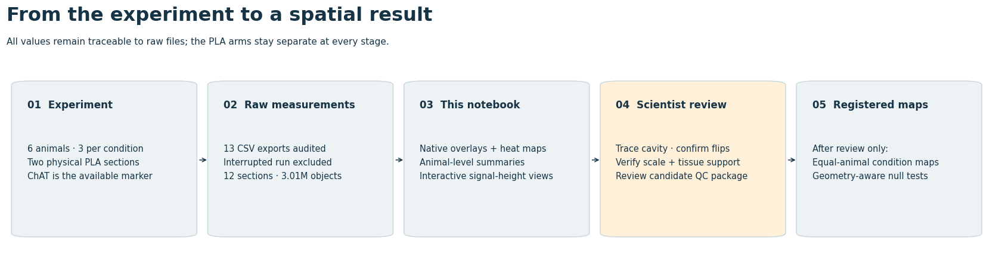

In [2]:
show(hp.workflow_figure(), '01_workflow')

## 2 · Load every CSV and establish provenance

Read all 13 files fresh, validate all rows, hash inputs and keep 12 primary exports. Do not reuse a previously aligned coordinate table. Job 4978 is superseded by 5403; the four byte-identical `Initial Data/` outline copies are audited but not concatenated. Object identity is **source file + Object Id**, never Object Id alone. Native x/y are bounding-box midpoints, not segmentation centroids.

In [3]:
objects, manifest = raw.load_complete_dataset(DATA, verify_hashes=True)
metadata = h.section_metadata(manifest)
summary = h.animal_summary(objects, metadata)
copies = raw.compare_initial_files(manifest, ROOT / 'Initial Data')
# Verify the interrupted/replacement relationship against every measurement field.
m = manifest.set_index('job')
short = raw.load_export(DATA / m.loc['4978', 'source_file'], m.loc['4978'].to_dict() | {'job':'4978'})
full = objects[objects.job == '5403']
repeat_audit = pd.DataFrame([raw.signature_overlap(short, full)])
del short, full
assert copies.identical_file.all()
assert repeat_audit.short_unmatched_rows.iloc[0] == 0
assert len(objects) == int(manifest.loc[manifest.is_primary, 'rows'].sum())
manifest.to_csv(TABLES / 'input_manifest.csv.gz', index=False, compression='gzip')
metadata.to_csv(TABLES / 'section_metadata.csv.gz', index=False, compression='gzip')
copies.to_csv(TABLES / 'initial_copy_audit.csv.gz', index=False, compression='gzip')
summary.to_csv(TABLES / 'animal_summary.csv.gz', index=False, compression='gzip')
display(Markdown(f'**Loaded {len(manifest)} exports; retained {len(metadata)} distinct sections and {len(objects):,} objects.** '
                 f'{sum(objects.object_type == "PLA"):,} PLA; {sum(objects.object_type == "ChAT"):,} ChAT. '
                 f'{len(copies)} original outline files are exact copies.'))
table(repeat_audit, 'interrupted_repeat_audit')
display(metadata[['job','animal_id','running_group','pla_arm','rows','image_label','marker_panel']])

**Loaded 13 exports; retained 12 distinct sections and 3,010,776 objects.** 310,024 PLA; 2,700,752 ChAT. 4 original outline files are exact copies.

,short_rows,full_rows,identical_measurement_rows,short_unmatched_rows,full_additional_rows
0,94409,190915,94409,0,96506


,job,animal_id,running_group,pla_arm,rows,image_label,marker_panel
0,4998,21F,Home cage,TDP43–HK1,323082,Image 1,ChAT
1,5006,21M,Running,TDP43–HK1,176423,Image 3,ChAT
2,4997,22F,Running,TDP43–HK1,163549,Image 1,ChAT
3,5001,22M,Running,TDP43–HK1,237144,Image 2,ChAT
4,5007,23M,Home cage,TDP43–HK1,306291,Image 3,ChAT
5,5002,24M,Home cage,TDP43–HK1,349776,Image 2,ChAT
6,5020,21F,Home cage,TDP43–PFKP,240702,Image 1,ChAT
7,5003,21M,Running,TDP43–PFKP,193552,Image 3,ChAT
8,5403,22F,Running,TDP43–PFKP,190915,Image 1,ChAT
9,4999,22M,Running,TDP43–PFKP,184684,Image 2,ChAT


In [4]:
qc_columns = ['job','is_primary','duplicate_ids','missing_values','nonpositive_area',
              'overlap_presence_mismatch','overlap_pct_formula_mismatch','any_zero_diameter',
              'zero_bbox_width_or_height','diameter_order_mismatch']
table(manifest[qc_columns], 'measurement_qc')
# Image labels are acquisition references, not additional biological replicates.
table(metadata.groupby(['image_label','pla_arm','running_group'], observed=True).size()
      .rename('sections').reset_index(), 'image_group_balance')

,job,is_primary,duplicate_ids,missing_values,nonpositive_area,overlap_presence_mismatch,overlap_pct_formula_mismatch,any_zero_diameter,zero_bbox_width_or_height,diameter_order_mismatch
0,4998,True,0,0,0,0,0,10405,9422,0
1,5020,True,0,0,0,0,0,7255,6705,0
2,4997,True,0,0,0,0,0,3472,3438,0
3,4978,False,0,0,0,0,0,1185,1267,0
4,5403,True,0,0,0,0,0,2448,2521,0
5,5001,True,0,0,0,0,0,4143,4007,0
6,4999,True,0,0,0,0,0,2291,2136,0
7,5002,True,0,0,0,0,0,13493,12222,0
8,5000,True,0,0,0,0,0,2360,1926,0
9,5006,True,0,0,0,0,0,6481,6060,0


,image_label,pla_arm,running_group,sections
0,Image 1,TDP43–HK1,Home cage,1
1,Image 1,TDP43–HK1,Running,1
2,Image 1,TDP43–PFKP,Home cage,1
3,Image 1,TDP43–PFKP,Running,1
4,Image 2,TDP43–HK1,Home cage,1
5,Image 2,TDP43–HK1,Running,1
6,Image 2,TDP43–PFKP,Home cage,1
7,Image 2,TDP43–PFKP,Running,1
8,Image 3,TDP43–HK1,Home cage,1
9,Image 3,TDP43–HK1,Running,1


**How to read QC:** zero diameters and degenerate boxes are reported, not silently removed. Area/flag definitions come from the export and require original-image review before assigning biological meaning. A valid numerical row can still be a segmentation artifact. Source-image references appear in both conditions; that does not establish matched acquisition settings, randomization or complete batch control.

Coordinate headers do not establish pixels or µm. All spatial axes therefore remain in **HALO export units**. Area and diameter retain the physical units explicitly named in their column headers; those units are not used to invent an x/y calibration. No object-area sum is treated as sampled tissue area.

In [5]:
fine = h.make_grids(objects, PARAMETERS['reconstruction_bin'])
geometry = h.make_grids(objects, PARAMETERS['geometry_bin'])
metrics = h.make_grids(objects, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])
surfaces = h.make_grids(objects, PARAMETERS['surface_bin'], PARAMETERS['min_pla_per_bin'])
for collection in (fine, geometry, metrics, surfaces):
    for job, grid in collection.items():
        assert int(grid['n_all'].sum()) == int(m.loc[job,'rows'])
for job, grid in metrics.items():
    np.savez_compressed(ARRAYS / f'job_{job}_metrics.npz', **grid)
for job, grid in fine.items():
    np.savez_compressed(ARRAYS / f'job_{job}_reconstruction.npz', **grid)
reviews = h.load_reviews(REVIEW_PATH, metadata, geometry)
# Do not overwrite reviewer decisions on a rerun.
if not REVIEW_PATH.exists():
    REVIEW_PATH.write_text(json.dumps(reviews, indent=2) + '\n')
status = h.review_status(reviews)
print('All four grid resolutions conserve every primary object count.')

All four grid resolutions conserve every primary object count.


<a id="explore"></a>
## Interactive control center · start with the data

**Three tabs, one set of measurements:**
- **3D measurements:** rotate and zoom; choose PLA/ChAT count, ChAT-positive fraction, mean PLA size, large-PLA fraction or actual overlap area. Filter by PLA arm, running group and animal. Change the bin size and minimum PLA denominator.
- **Channel overlay:** independently switch PLA and ChAT on/off, change opacity, and select ChAT-positive or ChAT-negative PLA. This view retains the fine 100-unit reconstruction.
- **Overlapping layers:** use the flat overlay or exploded 3D stack; show all sections, toggle individual layers, or step through them one at a time. The stack's vertical axis is **display order**, not anatomical depth.

Native coordinates show all available sections. Candidate-centered mode translates only the available geometric proposals and is restricted to **geometry QC**, because orientation, scale and anatomy have not been reviewed. Missing proposals are named, not invented. Reviewed mode becomes available section by section only after all review requirements pass. The two PLA arms never share a layer stack.

These controls are embedded in the notebook and work without a live kernel after rendering. **GitHub disables notebook JavaScript:** open the downloaded notebook in JupyterLab or VS Code, trust the reviewed file and Run All. Static companions below support readers using GitHub.

In [6]:
display(HTML(explorer_html(fine, geometry, surfaces, metrics, metadata, reviews)))

<a id="native"></a>
## 3 · See the tissue: native reconstructed overlays

Each panel overlays **PLA counts in color** on **ChAT counts in gray**, at 100-export-unit bins. Both layers use log color scales; colors are consistent within an arm. A colored bin is not proof of ChAT colocalization—the exported ChAT-presence flag defines that metric later. The side-by-side channel maps below help avoid overinterpreting blended colors. [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

These are direct, unsmoothed data reconstructions. Small puncta are located at their box midpoints; the zoom panel later shows original box extents. Every saved figure has a **300-DPI PNG and an SVG**, and the fine-grid counts are stored losslessly. Export resolution improves legibility, not biological resolution.

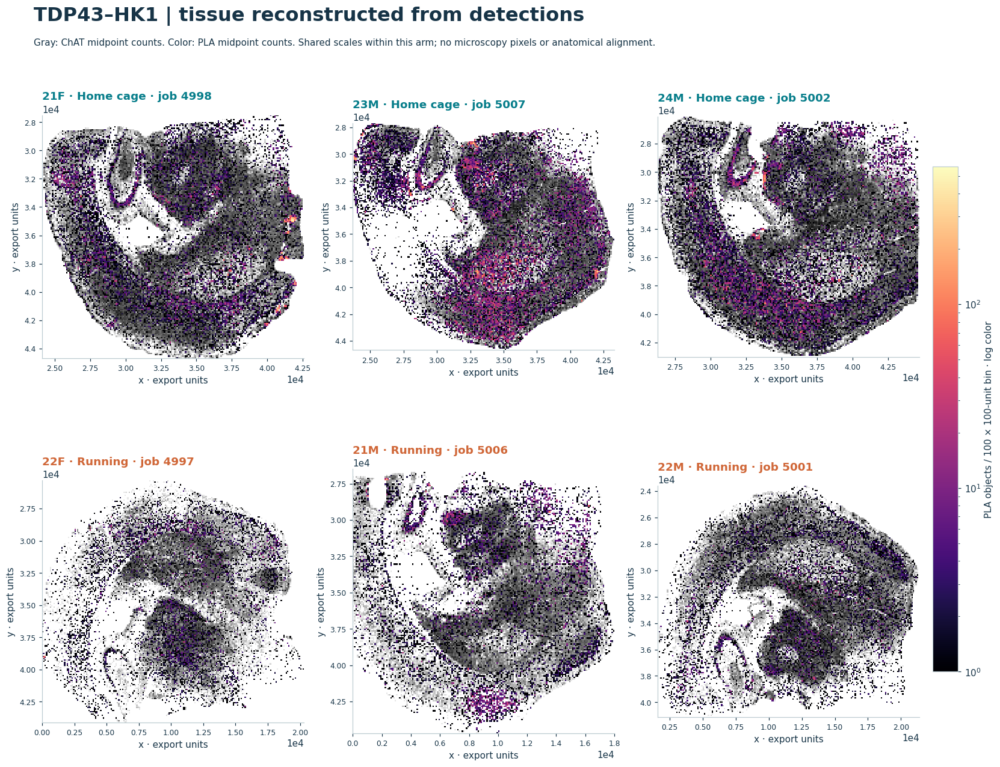

In [7]:
show(hp.native_atlas(fine, metadata, 'TDP43–HK1'), '02_native_overlay_hk1')

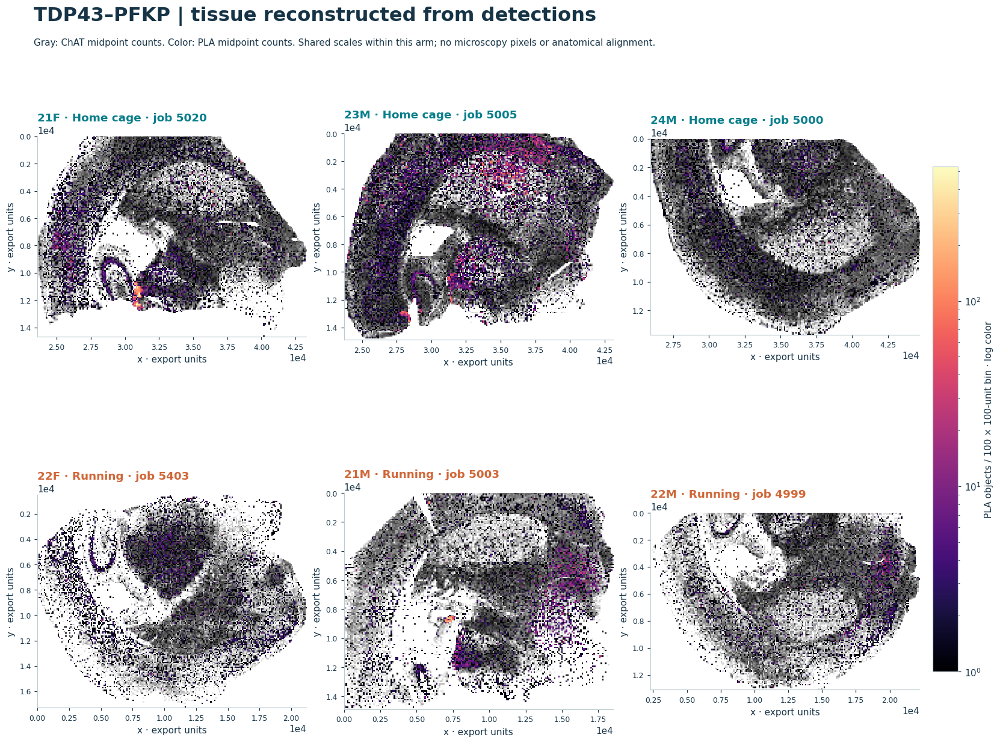

In [8]:
show(hp.native_atlas(fine, metadata, 'TDP43–PFKP'), '02_native_overlay_pfkp')

<a id="registration"></a>
## 4 · Registration review comes before anatomical comparison

The handoff prescribes a traced ventricular cavity, a geometric polygon centroid, a reviewed choice of **none / horizontal / vertical / both flips**, then translation to the cavity center. It prohibits fitting continuous rotations, rescaling or warping to improve agreement. A landmark-centered coordinate system preserves shape but cannot make different section levels anatomically equivalent. [Handoff, pp. 4–9](HALO_spatial_analysis_raw_data_handoff.pdf).

**First-pass proposal method:** use the union of all PLA and ChAT detections on a 250-unit grid; close occupied bins with two iterations of a 3×3 cross; identify enclosed holes; trace the largest hole if it covers at least six bins. This uses overall geometry, not a ChAT-positive subset or a Running-effect hotspot. It is a reproducible *proposal generator*, not a validated ventricular detector. Closing can fragment, shrink or bridge gaps. The polygon is traced around the resulting component and its area centroid is calculated by the shoelace formula.

**Current status:** none of the sections has a signed-off anatomical trace, orientation, scale or tissue mask. All previews retain `none` as an unapproved flip choice. Missing cavity proposals remain missing. Review each polygon against the native data, especially the complex left-side void in 23M/HK1; several traces cover only part of the visible cavity. Do not advance these proposals automatically.

In [9]:
table(status, 'registration_gate')

,job,animal_id,pla_arm,candidate_found,ready,needs_review
0,4998,21F,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
1,5006,21M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
2,4997,22F,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
3,5001,22M,TDP43–HK1,False,False,"ventricular trace, orientation, common scale, ..."
4,5007,23M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
5,5002,24M,TDP43–HK1,True,False,"ventricular trace, orientation, common scale, ..."
6,5020,21F,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."
7,5003,21M,TDP43–PFKP,False,False,"ventricular trace, orientation, common scale, ..."
8,5403,22F,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."
9,4999,22M,TDP43–PFKP,True,False,"ventricular trace, orientation, common scale, ..."


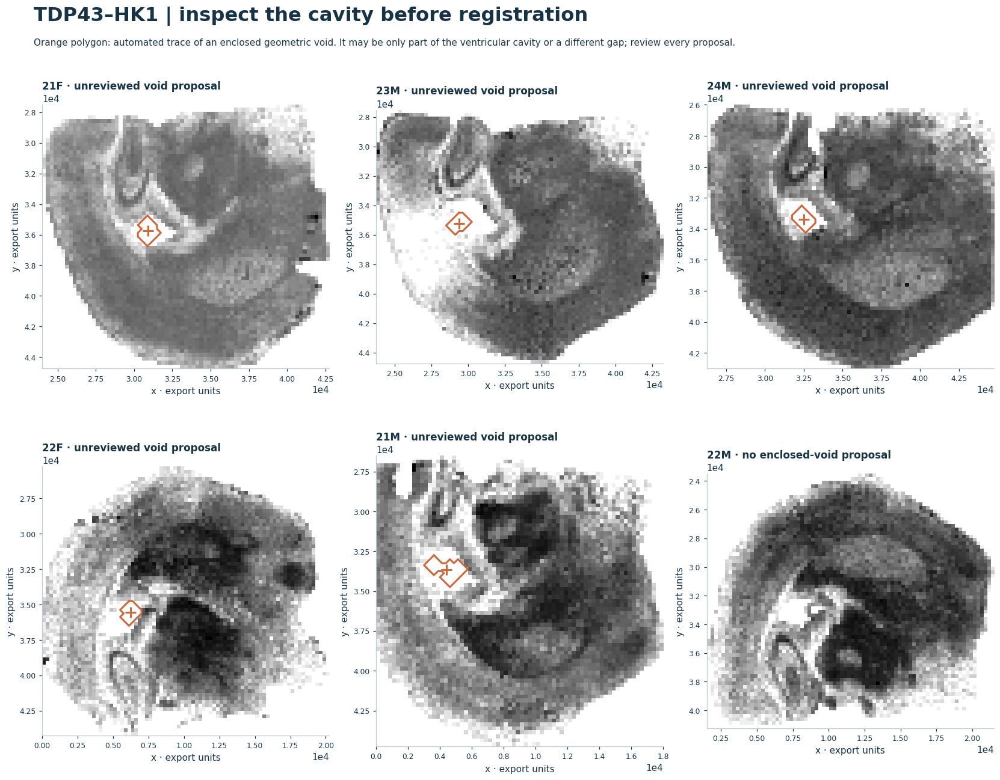

In [10]:
show(hp.landmark_atlas(geometry, reviews, 'TDP43–HK1'), '03_landmark_proposals_hk1')

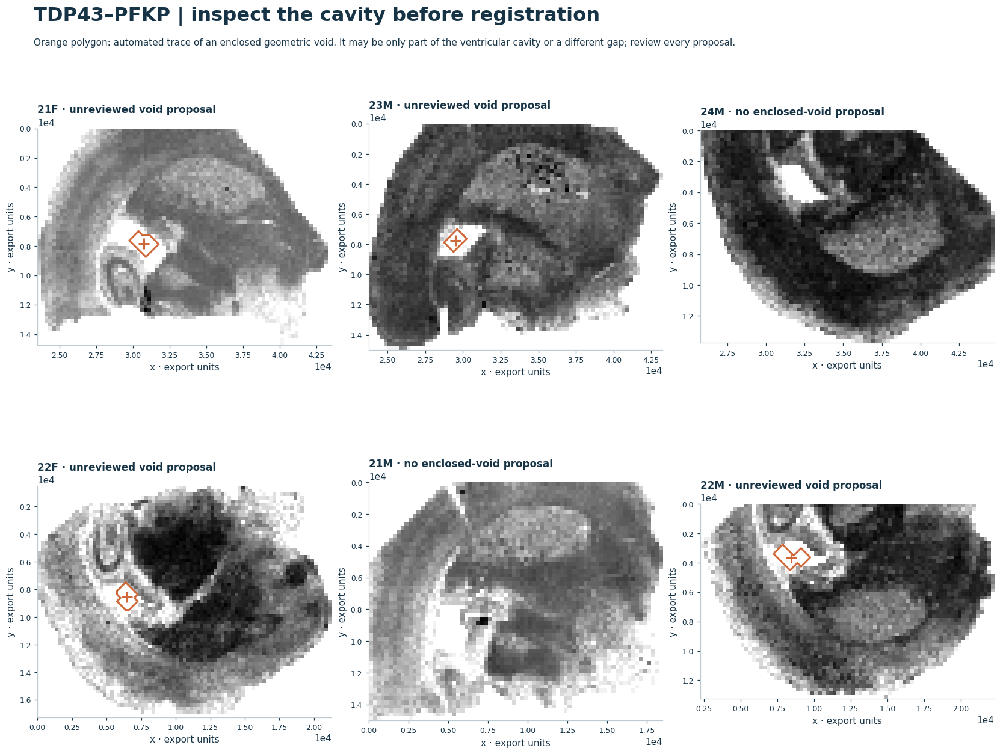

In [11]:
show(hp.landmark_atlas(geometry, reviews, 'TDP43–PFKP'), '03_landmark_proposals_pfkp')

### How the dimensions overlap after a proposed translation

The next two overlays answer a **geometry-review question**, not a biological one: how different are section silhouettes after placing their *candidate* centers at the origin? The orange/green/blue outlines identify animals; no contour is stretched to match another. Sections without a qualifying candidate are omitted and named beneath each figure. Morphological closing is used only to draw readable contours.

The handoff notes an expected straight cut edge. A straight edge, including one at coordinate zero, is **not automatically clipping**. All support labels remain uncertain until an image/ROI review can distinguish the expected cut from actual missing tissue.

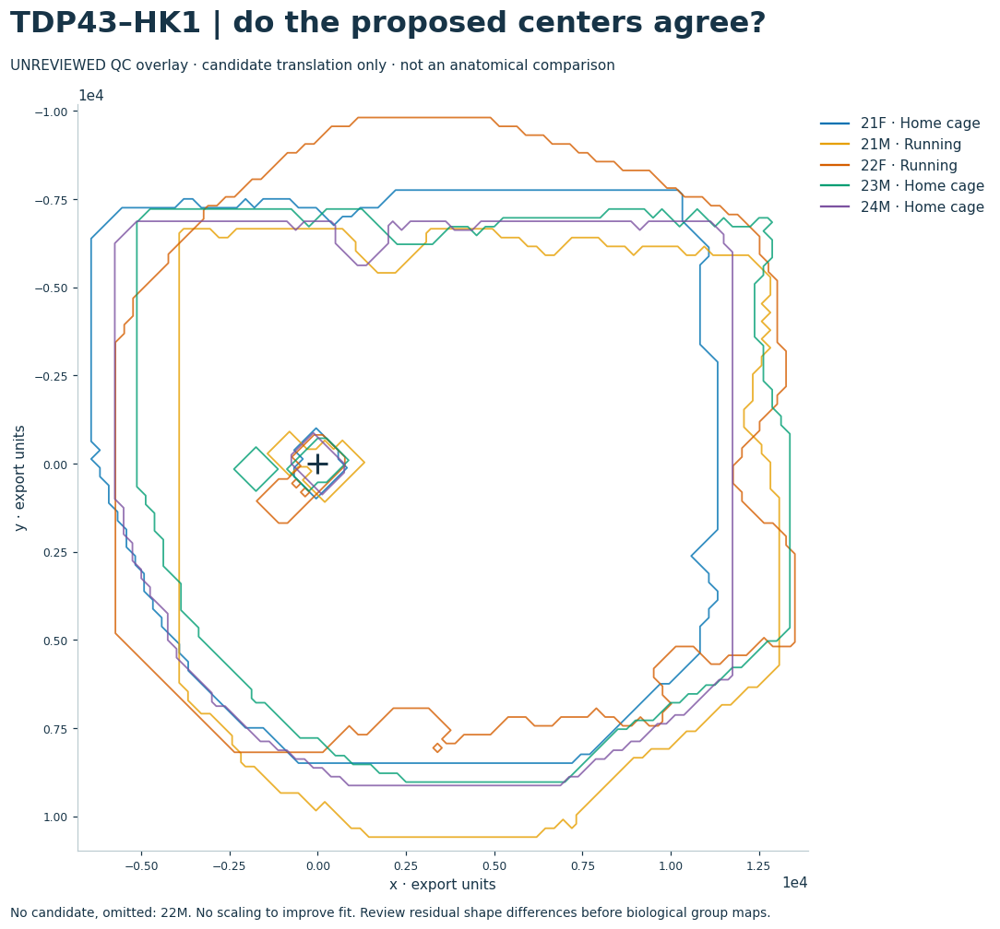

In [12]:
show(hp.silhouette_overlay(geometry, reviews, 'TDP43–HK1'), '04_candidate_outline_overlay_hk1')

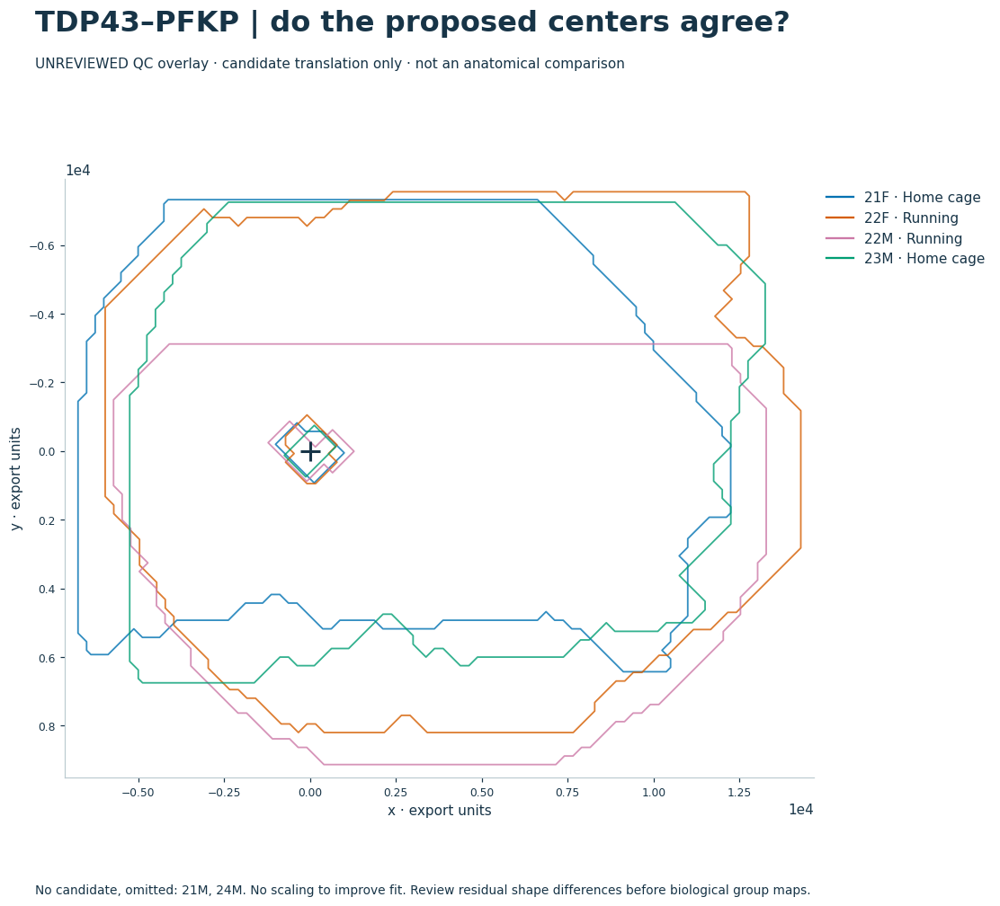

In [13]:
show(hp.silhouette_overlay(geometry, reviews, 'TDP43–PFKP'), '04_candidate_outline_overlay_pfkp')

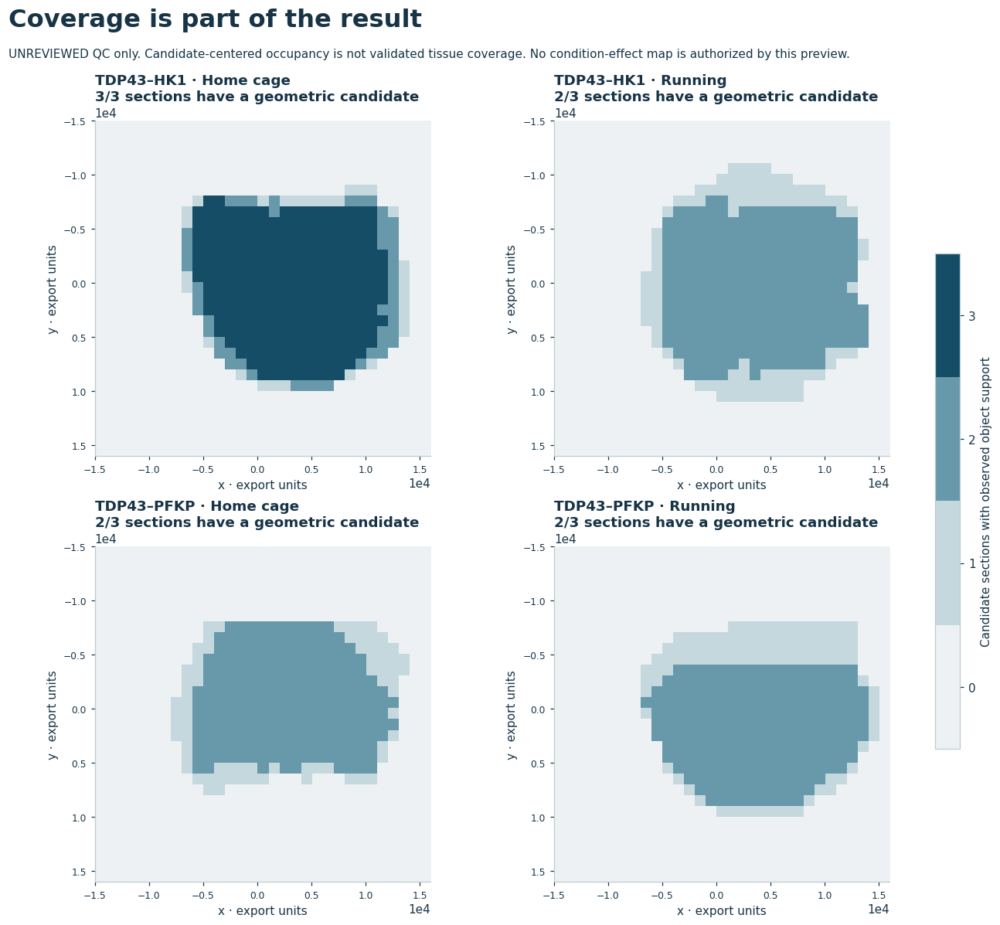

| Animal | PLA arm | Section QC | Flip review |
|---|---|---|---|
| 21F | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4998.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4998.png) |
| 21M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5006.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5006.png) |
| 22F | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4997.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4997.png) |
| 22M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5001.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5001.png) |
| 23M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5007.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5007.png) |
| 24M | TDP43–HK1 | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5002.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5002.png) |
| 21F | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5020.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5020.png) |
| 21M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5003.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5003.png) |
| 22F | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5403.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5403.png) |
| 22M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_4999.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_4999.png) |
| 23M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5005.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5005.png) |
| 24M | TDP43–PFKP | [Native / cavity / support](outputs/spatial_handoff/figures/qc_job_5000.png) | [Four orientation choices](outputs/spatial_handoff/figures/flips_job_5000.png) |

In [14]:
coverage = h.provisional_coverage(geometry, reviews)
show(hp.coverage_figure(coverage), '05_candidate_coverage')
# Save native/landmark/support and all four flip comparisons for every section.
qc_links = []
for r in reviews:
    job = r['job']
    for name, fig in [(f'qc_job_{job}', hp.qc_section(geometry[job], r)),
                      (f'flips_job_{job}', hp.flip_figure(geometry[job], r))]:
        hp.save(fig, OUT, name); plt.close(fig)
    qc_links.append(f'| {r["animal_id"]} | {r["pla_arm"]} | '
                    f'[Native / cavity / support](outputs/spatial_handoff/figures/qc_job_{job}.png) | '
                    f'[Four orientation choices](outputs/spatial_handoff/figures/flips_job_{job}.png) |')
display(Markdown('| Animal | PLA arm | Section QC | Flip review |\n|---|---|---|---|\n'+'\n'.join(qc_links)))

**Support is not tissue area.** Here, an occupied all-object geometry bin is provisional evidence of sampling. An empty bin is unknown, not a biological zero; a dense marker field can also hide a tear. True ROI polygons are preferred. The coverage figure counts candidate sections with observations and is labeled as QC because neither alignment nor coverage has passed review.

**Explicit first-pass exception:** the following native-coordinate marker maps and whole-section summaries are descriptive review products. They do not depend on a common anatomical origin. Registered Running-minus-Home biological maps, tissue-area densities and spatial enrichment tests remain withheld until the handoff's review gates pass. This exception permits inspection of the available data without turning unreviewed geometry into biological localization.

<a id="maps"></a>
## 5 · Heat maps with visible denominators

For each 1,000 × 1,000-export-unit bin, the association map is

**Association (%) = 100 × ChAT-positive PLA count / all PLA count in that bin.**

Show a value only with **at least 10 PLA objects**. Pale gray means other objects were observed but the PLA denominator is too small. White means no object support. A zero among sufficient PLA observations is a measured zero; a missing bin is NA. No smoothing, imputation or animal pooling is applied. The shared 0–100% scale makes fractions comparable as measurements, without implying anatomical correspondence.

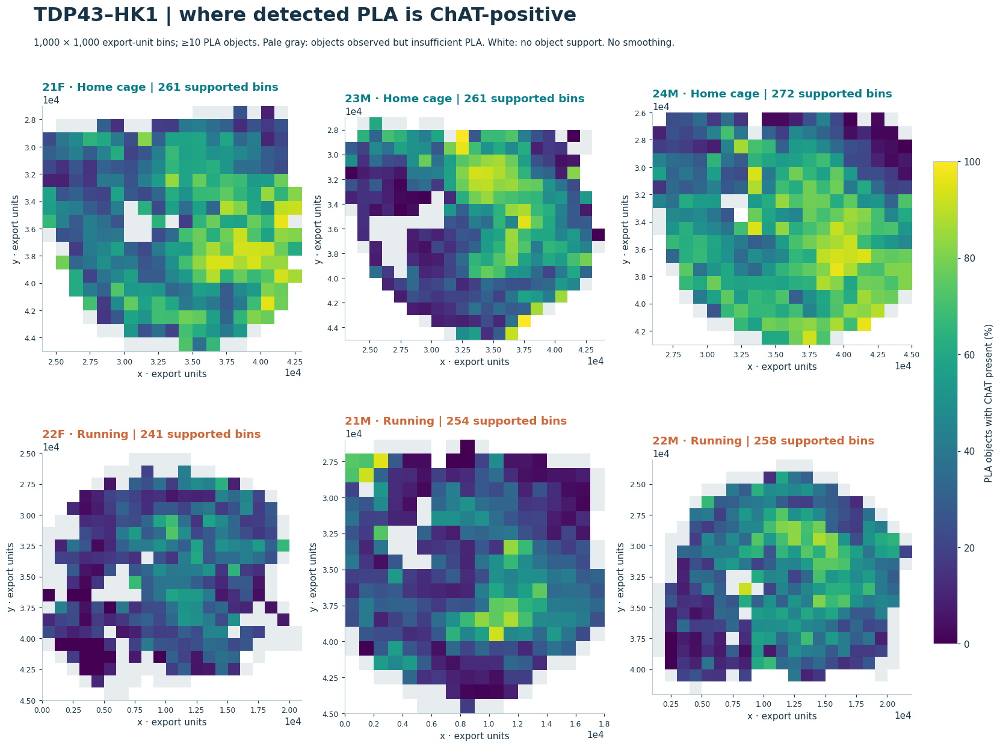

In [15]:
show(hp.fraction_atlas(metrics, metadata, 'TDP43–HK1'), '06_fraction_atlas_hk1')

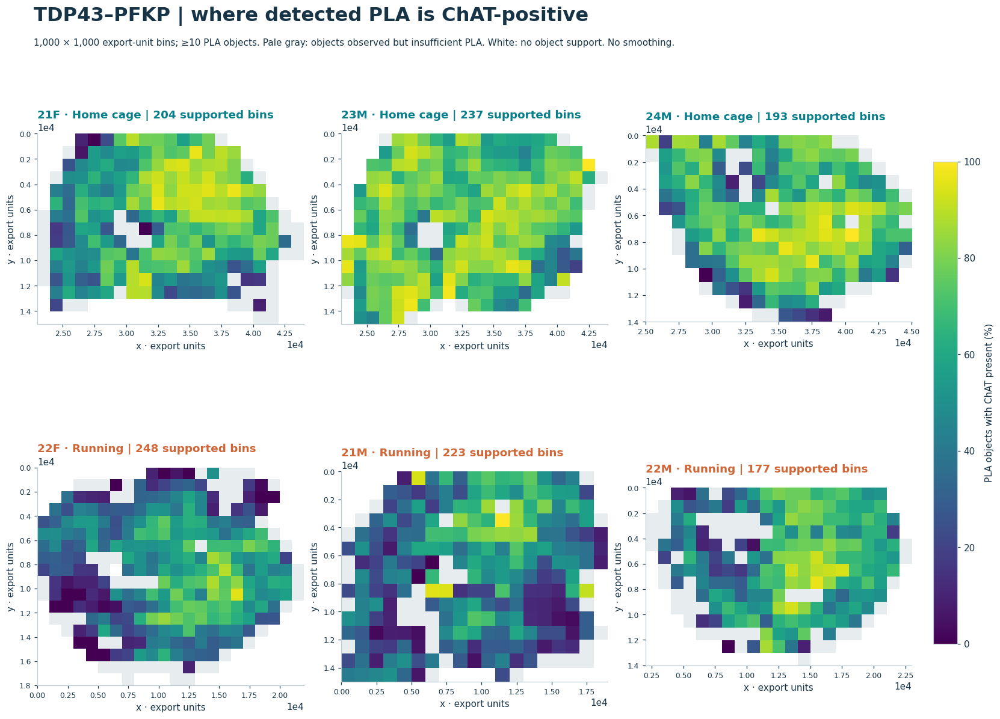

In [16]:
show(hp.fraction_atlas(metrics, metadata, 'TDP43–PFKP'), '06_fraction_atlas_pfkp')

### Zoom through every section

The left panel is the reconstructed overlay, the middle panel the supported ChAT-positive PLA fraction, and the right panel its PLA denominator. Move the slider to another animal. Wheel/pinch to zoom, drag to select a window, double-click to reset. Coordinates stay native, so reference them when requesting a microscopy review. The controls are embedded in the saved notebook; no web service or API is needed.

In [17]:
explorer_hk1 = hp.interactive_native(fine, metrics, metadata, 'TDP43–HK1')
explorer_hk1.show(config=PLOT_CONFIG)

In [18]:
explorer_pfkp = hp.interactive_native(fine, metrics, metadata, 'TDP43–PFKP')
explorer_pfkp.show(config=PLOT_CONFIG)

### Complementary readouts: a high fraction is only one part of the story

The six-panel views separate PLA detections, independent ChAT detections, association, **whole area of ChAT-positive PLA objects**, mean PLA size, and fraction of PLA at least 1 µm². The area of marker-positive PLA objects is different from the actual overlapping area. Both are exported. Sums of object areas can double-count overlapping objects and are not total tissue coverage.

The displayed 21F sections are a fixed example per arm, not selected for a condition effect. The same six-panel output is generated for **all 12 sections** in the figure directory. Large-area cutoffs are exploratory and fixed across animals, not biological aggregate definitions.

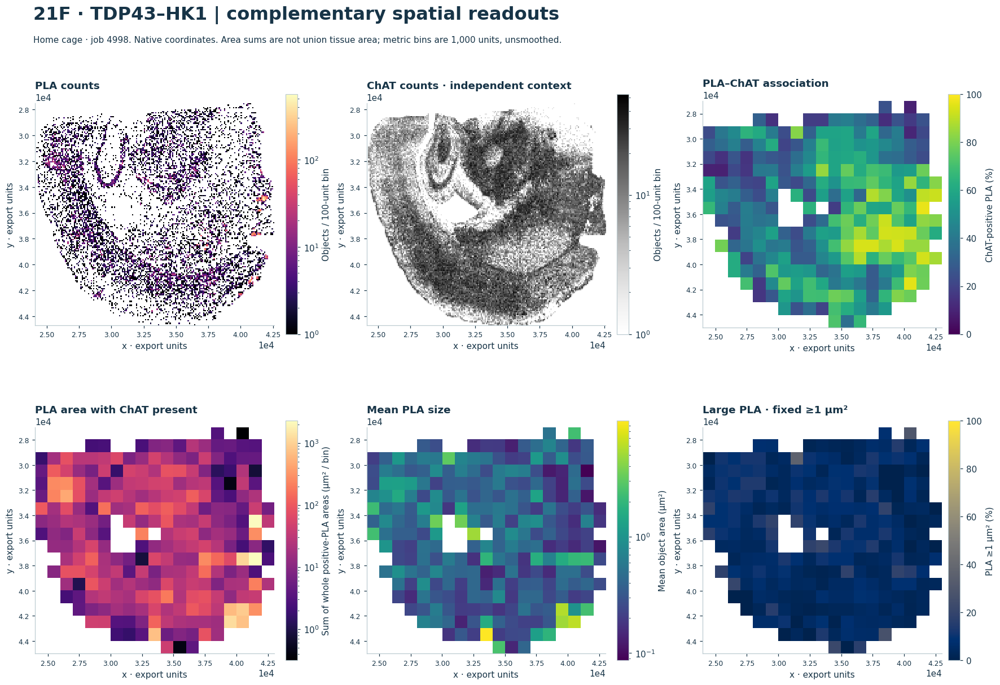

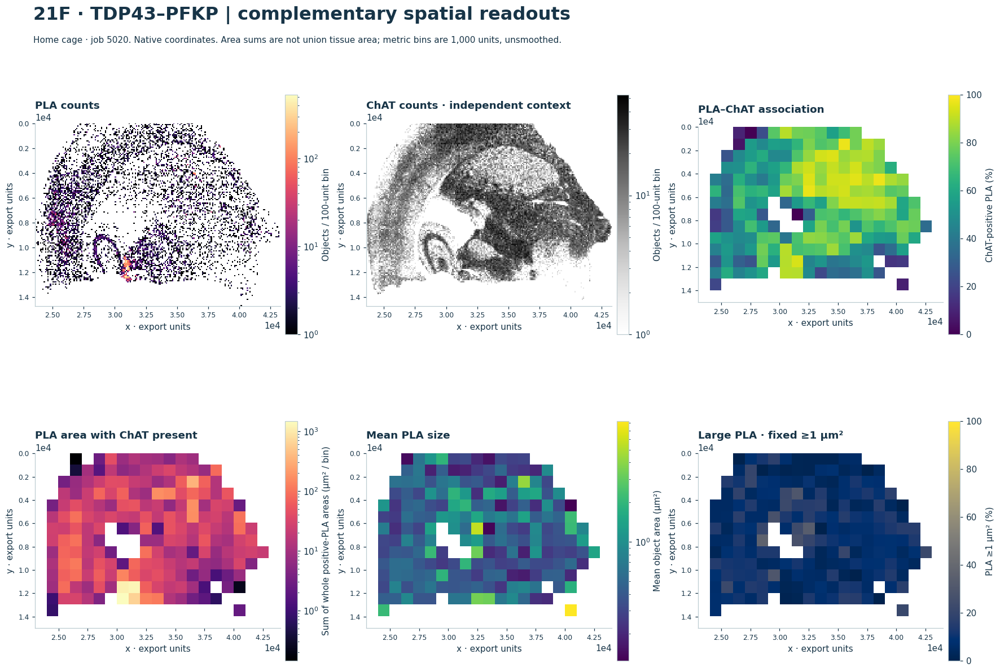

In [19]:
for row in metadata.itertuples():
    fig = hp.detailed_section(fine[str(row.job)], metrics[str(row.job)], row)
    hp.save(fig, OUT, f'07_section_{row.job}_six_metrics')
    if row.animal_id == '21F': display(fig)
    plt.close(fig)

<a id="three-d"></a>
## 6 · Interactive 3D signal-height surfaces

**Rotate with the mouse, scroll/pinch to zoom, and use the section slider.** “Look down” returns to a plan view. Each arm has its own viewer. Hover reports raw PLA counts, ChAT counts and supported association. The height is **log(1 + PLA count per 500 × 500-unit bin)**, with tick labels showing counts. This exposes low-count structure without clipping extreme peaks; it is a display transform, not a statistical adjustment. The height/color scale is shared across animals within each arm.

The x:y aspect ratio preserves native section proportions. Height is deliberately a different unit. Surface facets connect neighboring bin centers only for display, with gaps where object support is absent. Native dimensions, heat-map pixels and exact bin counts remain available in the 2D views. There is **no measured z**, no assumed thickness and no interpolation between animals or PLA arms.

In [20]:
surface_hk1 = hp.interactive_surface(surfaces, metadata, 'TDP43–HK1')
surface_hk1.show(config=PLOT_CONFIG)

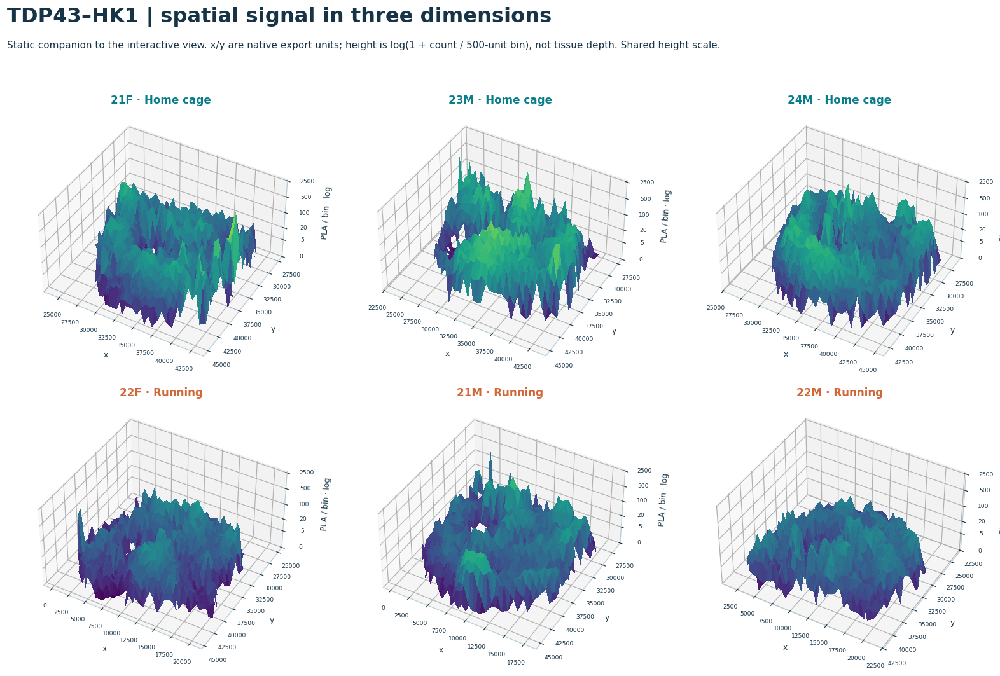

In [21]:
show(hp.surface_preview(surfaces, metadata, 'TDP43–HK1'), '08_surface_companion_hk1')

In [22]:
surface_pfkp = hp.interactive_surface(surfaces, metadata, 'TDP43–PFKP')
surface_pfkp.show(config=PLOT_CONFIG)

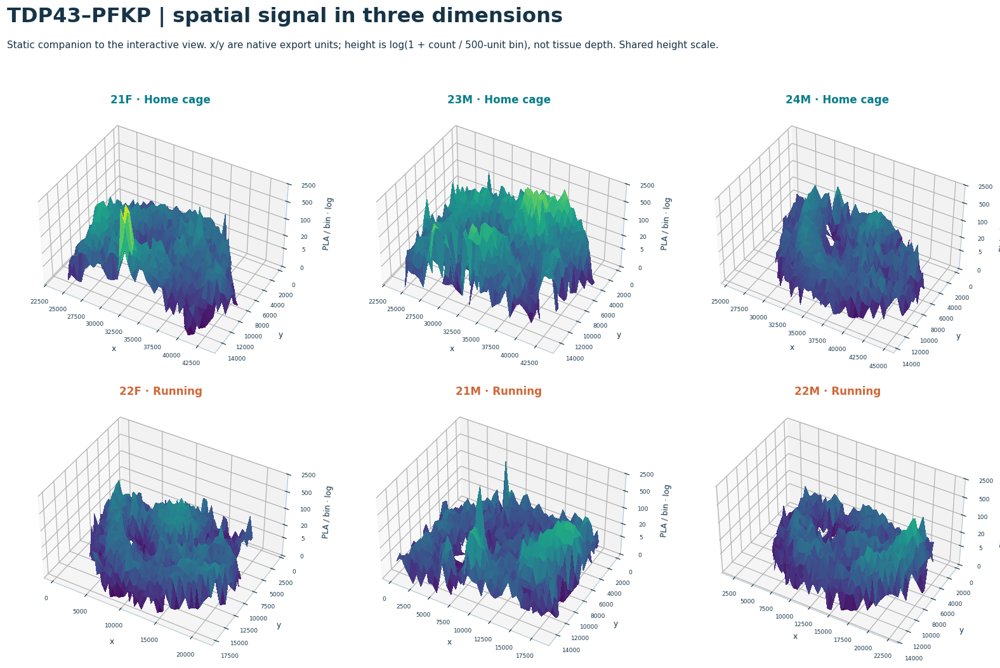

In [23]:
show(hp.surface_preview(surfaces, metadata, 'TDP43–PFKP'), '08_surface_companion_pfkp')

<a id="findings"></a>
## 7 · What changes at the animal level?

Whole-section summaries can be compared without claiming spatial registration. Each animal contributes one value **within each arm**, with equal weight. Detected puncta are nested measurements, not biological replicates. With three animals per condition, these are exploratory effect descriptions, not population-level confirmation. No cell-level or pixelwise p-values are fitted. [Lazic, 2010](https://pmc.ncbi.nlm.nih.gov/articles/PMC2817684/).

The left column asks what fraction of PLA is ChAT-positive. The middle column asks what fraction of PLA object area lies in those positive objects—**not** what fraction of tissue is colocalized. The right column shows independent ChAT detection counts, which help identify changes in marker opportunity or sampling. Counts are not normalized tissue density and are not neuron counts.

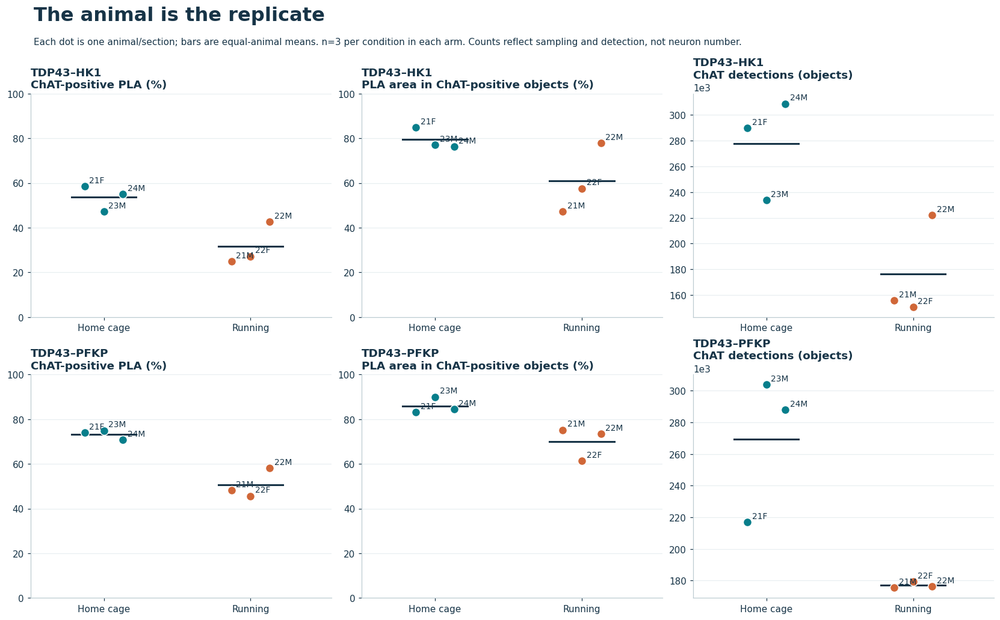

,pla_arm,metric,n_home,n_running,home_mean,running_mean,running_minus_home,leave_pair_out_min,leave_pair_out_max
0,TDP43–HK1,pla_association_pct,3,3,53.586,31.580,-22.006,-30.798,-16.156
1,TDP43–PFKP,pla_association_pct,3,3,73.203,50.618,-22.585,-27.593,-19.219


**TDP43–HK1:** Home cage **53.59%**, Running **31.58%**; Running − Home **-22.01 percentage points**. Deleting one animal from each group in all nine combinations gives **-30.80 to -16.16 points**. This is a sensitivity range, **not a confidence interval**.

**TDP43–PFKP:** Home cage **73.20%**, Running **50.62%**; Running − Home **-22.58 percentage points**. Deleting one animal from each group in all nine combinations gives **-27.59 to -19.22 points**. This is a sensitivity range, **not a confidence interval**.

,animal_id,running_group,pla_arm,pla_objects,pla_with_chat,pla_association_pct,pla_total_area_um2,marker_positive_pla_area_um2,actual_overlap_area_um2,chat_objects
0,21F,Home cage,TDP43–HK1,33438,19574,58.538,"23,175.774","19,686.165","13,488.469",289644
1,21F,Home cage,TDP43–PFKP,23857,17639,73.936,"13,209.306","10,969.747","8,507.084",216845
2,22F,Running,TDP43–HK1,12644,3437,27.183,"8,438.703","4,855.773","2,012.327",150905
3,22F,Running,TDP43–PFKP,11589,5287,45.621,"7,160.049","4,389.130","2,035.998",179326
4,22M,Running,TDP43–HK1,14984,6402,42.726,"10,266.367","7,992.291","3,840.487",222160
5,22M,Running,TDP43–PFKP,8412,4893,58.167,"4,344.564","3,192.802","1,919.583",176272
6,24M,Home cage,TDP43–HK1,41237,22710,55.072,"21,662.494","16,525.121","9,348.140",308539
7,24M,Home cage,TDP43–PFKP,7733,5470,70.736,"4,627.052","3,913.245","2,344.615",287944
8,21M,Running,TDP43–HK1,20478,5085,24.832,"16,157.550","7,624.159","2,495.491",155945
9,21M,Running,TDP43–PFKP,18160,8729,48.067,"13,228.260","9,947.806","4,384.953",175392


In [24]:
show(hp.group_summary_figure(summary), '09_equal_animal_summary')
contrasts = h.group_contrasts(summary)
table(contrasts, 'equal_animal_association_contrasts')
for r in contrasts.itertuples():
    display(Markdown(f'**{r.pla_arm}:** Home cage **{r.home_mean:.2f}%**, Running **{r.running_mean:.2f}%**; '
                     f'Running − Home **{r.running_minus_home:.2f} percentage points**. '
                     f'Deleting one animal from each group in all nine combinations gives '
                     f'**{r.leave_pair_out_min:.2f} to {r.leave_pair_out_max:.2f} points**. '
                     'This is a sensitivity range, **not a confidence interval**.'))
table(summary[['animal_id','running_group','pla_arm','pla_objects','pla_with_chat','pla_association_pct',
               'pla_total_area_um2','marker_positive_pla_area_um2','actual_overlap_area_um2','chat_objects']],
      'animal_denominators_and_areas')

**Interpretation:** a lower Running-group fraction occurs in both independently analyzed arms. It describes the detected PLA–ChAT relationship in these six animals, not “less binding,” loss of cholinergic neurons, reduced glycolysis, or a causal running effect. ChAT object counts also differ, so lower marker opportunity, section geometry, detection thresholds or technical variation remain plausible contributors. The smaller size-specific gap in some bins does not eliminate those alternatives.

The leave-pair-out calculation checks whether removing any one animal in each condition reverses the descriptive direction. It does not measure the uncertainty of future animals. Specifying biological replicates, controls and an adequately sized follow-up experiment takes priority over fitting a more elaborate model to these same six animals.

### Size-dependent association and filter sensitivity

Fixed size bins are **[0, 0.03), [0.03, 0.1), [0.1, 0.3), [0.3, 1), [1, ∞) µm²**. The right column repeats the whole-section calculation after several minimum-area filters; each retained object is still counted once, and animals are still averaged equally. Thin curves show individuals so a group curve cannot hide one anomalous animal.

A rise with size can reflect increased geometric opportunity to overlap ChAT, merged detections, or genuine compartment association. This plot alone cannot distinguish those mechanisms. Use the exported size-bin denominators and microscopy controls before interpreting large PLA as complexes or aggregates.

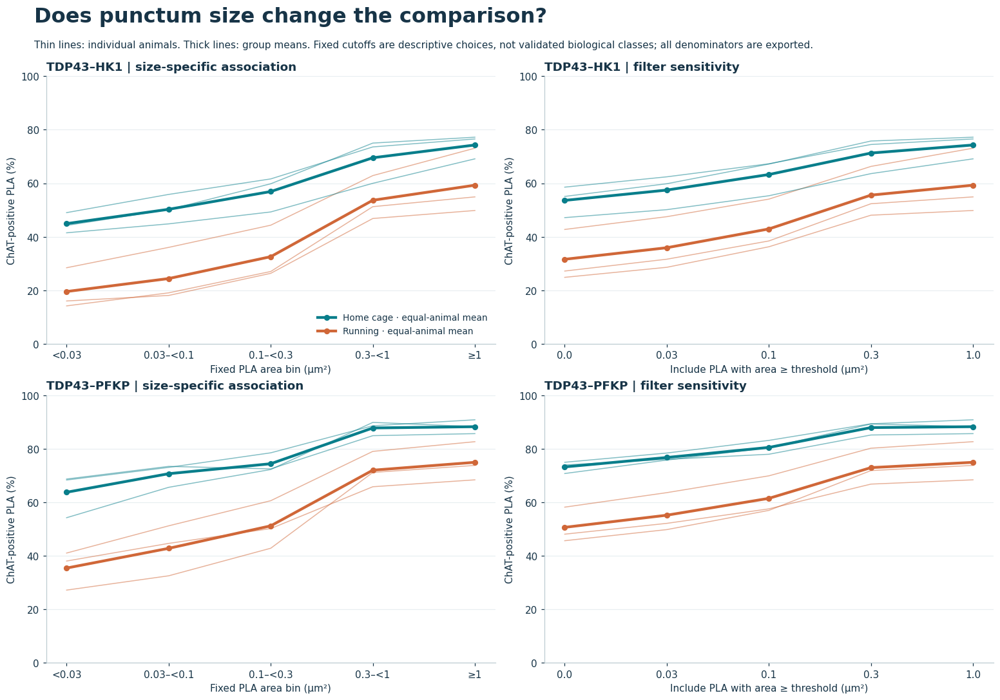

running_group         Home cage  Running
pla_arm    size_bin                     
TDP43–HK1  0.03–<0.1     50.261   24.373
           0.1–<0.3      56.895   32.552
           0.3–<1        69.515   53.640
           <0.03         44.906   19.524
           ≥1            74.291   59.267
TDP43–PFKP 0.03–<0.1     70.666   42.770
           0.1–<0.3      74.390   51.179
           0.3–<1        87.764   71.978
           <0.03         63.733   35.400
           ≥1            88.236   74.921

In [25]:
size_bins, sensitivity = h.size_tables(objects, metadata)
size_bins.to_csv(TABLES / 'size_bin_denominators.csv.gz', index=False, compression='gzip')
sensitivity.to_csv(TABLES / 'area_filter_sensitivity.csv.gz', index=False, compression='gzip')
show(hp.size_figure(size_bins, sensitivity), '10_size_and_filter_sensitivity')
size_means = size_bins.groupby(['pla_arm','running_group','size_bin'], observed=True).fraction_pct.mean().reset_index()
display(size_means.pivot(index=['pla_arm','size_bin'], columns='running_group', values='fraction_pct'))

## 8 · Nearest ChAT midpoint: a complementary spatial description

Compute the Euclidean distance from each PLA midpoint to the closest ChAT midpoint **in the same section** with a k-d tree. This is a center-to-center distance, not membrane distance, molecular separation or an alternative definition of HALO overlap. A large ChAT object can overlap PLA while their midpoints remain far apart.

Solid curves use all PLA. Dashed curves retain PLA with at least **500 export units** of conservative distance from unsampled support and whose nearest neighbor is closer than that boundary. Boundary clearance comes from the occupied 250-unit all-object grid, reduced by half the cell diagonal. Internal gaps count as boundaries; this intentionally conservative sensitivity analysis may exclude valid tissue and does not substitute for an ROI mask. Curves are per animal; x-axis display stops at the largest 99th percentile, while full quantile tables include the tail.

Distance units and support are unverified, so these curves are **within-section descriptive diagnostics**. They do not establish between-animal physical distance differences or attraction. A formal enrichment claim needs a tissue- and abundance-aware spatial null, not unrestricted random point placement or pixel shuffling. [Shivanandan et al., 2013](https://pubmed.ncbi.nlm.nih.gov/24299066/), [Dunn et al., 2011](https://pubmed.ncbi.nlm.nih.gov/21209361/).

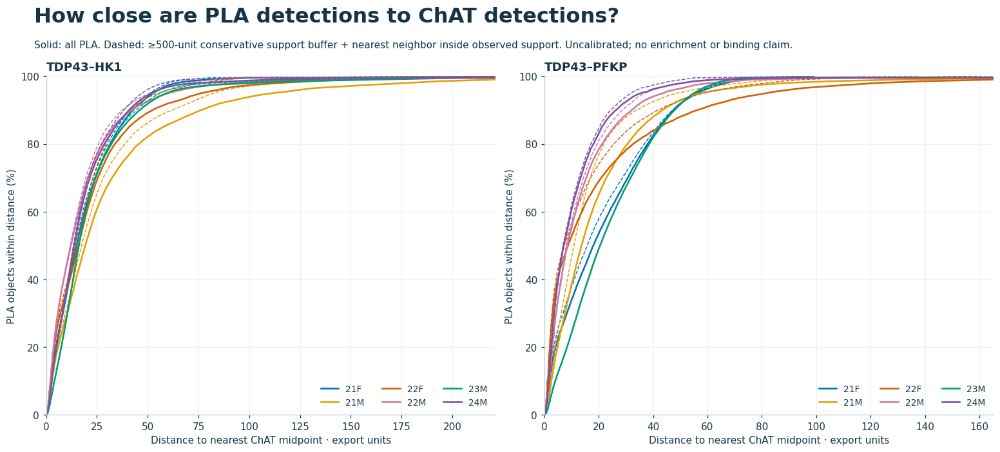

,job,n_pla,n_interior,retained_pct,median_all,median_interior,q95_all,animal_id,pla_arm,running_group
0,4997,12644,10780,85.258,15.890,14.705,76.449,22F,TDP43–HK1,Running
1,4998,33438,28690,85.801,15.008,14.422,52.559,21F,TDP43–HK1,Home cage
2,4999,8412,7700,91.536,8.500,8.062,43.718,22M,TDP43–PFKP,Running
3,5000,7733,6859,88.698,7.106,6.801,35.487,24M,TDP43–PFKP,Home cage
4,5001,14984,13416,89.536,12.104,11.853,60.253,22M,TDP43–HK1,Running
5,5002,41237,37885,91.871,13.757,13.463,51.620,24M,TDP43–HK1,Home cage
6,5003,18160,12786,70.407,13.657,10.966,57.489,21M,TDP43–PFKP,Running
7,5005,45123,39776,88.150,20.524,20.427,55.057,23M,TDP43–PFKP,Home cage
8,5006,20478,16429,80.228,19.235,17.500,111.553,21M,TDP43–HK1,Running
9,5007,72369,65106,89.964,16.101,16.101,59.237,23M,TDP43–HK1,Home cage


In [26]:
proximity_curves, proximity_summary = h.proximity_analysis(objects, metadata, geometry,
                                                          PARAMETERS['edge_buffer_export_units'])
proximity_curves.to_csv(TABLES / 'nearest_chat_quantile_curves.csv.gz', index=False, compression='gzip')
show(hp.proximity_figure(proximity_curves), '11_nearest_chat_distance')
table(proximity_summary, 'nearest_chat_summary')

<a id="actions"></a>
## 9 · Where the scientist should look next

The following review windows are chosen by **declared rules**: the highest PLA-count bin and the highest supported ChAT-positive fraction bin in each section. They are audit targets, not representative-field estimates or evidence of an anatomical hotspot. Coordinates are native, so the scientist can find the same windows in the original image. Ties use the first grid bin in row-major order; review both extreme and ordinary fields when validating segmentation.

,job,animal_id,pla_arm,reason,xmin,xmax,ymin,ymax,n_pla,n_chat,positive_pct
0,4998,21F,TDP43–HK1,largest PLA count,"41,000.000","42,000.000","34,000.000","35,000.000",3314,1474,90.585
1,4998,21F,TDP43–HK1,highest supported ChAT fraction,"41,000.000","42,000.000","35,000.000","36,000.000",1282,1270,96.490
2,5006,21M,TDP43–HK1,largest PLA count,"8,000.000","9,000.000","42,000.000","43,000.000",623,206,7.063
3,5006,21M,TDP43–HK1,highest supported ChAT fraction,"2,000.000","3,000.000","27,000.000","28,000.000",495,589,95.354
4,4997,22F,TDP43–HK1,largest PLA count,"11,000.000","12,000.000","29,000.000","30,000.000",207,1383,20.290
5,4997,22F,TDP43–HK1,highest supported ChAT fraction,"10,000.000","11,000.000","31,000.000","32,000.000",37,1467,72.973
6,5001,22M,TDP43–HK1,largest PLA count,"13,000.000","14,000.000","38,000.000","39,000.000",218,1297,42.661
7,5001,22M,TDP43–HK1,highest supported ChAT fraction,"8,000.000","9,000.000","33,000.000","34,000.000",61,231,91.803
8,5007,23M,TDP43–HK1,largest PLA count,"34,000.000","35,000.000","39,000.000","40,000.000",1712,491,76.402
9,5007,23M,TDP43–HK1,highest supported ChAT fraction,"32,000.000","33,000.000","28,000.000","29,000.000",24,12,100.000


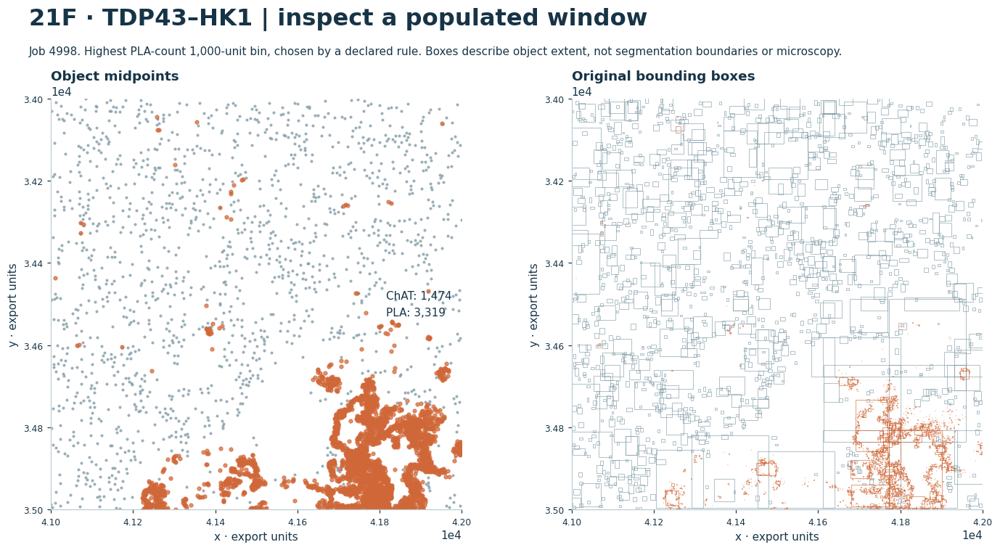

In [27]:
queue = h.spatial_review_queue(metrics, metadata)
table(queue.drop(columns='source_file'), 'image_review_windows')
queue.to_csv(TABLES / 'image_review_windows_with_sources.csv.gz', index=False, compression='gzip')
show(hp.zoom_boxes(objects, queue, '4998'), '12_midpoints_and_bounding_boxes')

### Actionable findings and decisions

| Observation / current limit | Next action | What it resolves |
|---|---|---|
| Lower Running ChAT-positive PLA fractions in both arms; all six animals are shown | Check ChAT segmentation and detection settings blinded to condition; use negative/single-antibody PLA controls and consistent acquisition | Whether detection opportunity or assay specificity explains the pattern |
| Larger PLA objects are more often ChAT-positive; extreme counts appear in localized windows | Review the coordinate queue plus ordinary fields in original channels; inspect merged objects and large-punctum boundaries | Whether size association reflects segmentation or compartment biology |
| ChAT detections vary across animals and conditions | Obtain HALO tissue ROI polygons and calibration; measure independent ChAT abundance per supported tissue area | Whether an apparent association shift accompanies a change in sampled marker opportunity |
| Nine enclosed-void proposals; three missing proposals; none approved | Manually trace full ventricular cavities, verify four-choice orientation, review expected cut edge and ambiguous cases with a second scientist | Whether an anatomical comparison is justified at all |
| No physical scale, z-stack or confirmed serial-section spacing | Supply original OME-TIFF/channel metadata, pixel size and section relationships | Calibrated image overlays; true 3D only if actual z/serial-section data exist |
| Only one marker panel and n=3 per condition | Plan additional animals, matched section levels, fixed analysis rules and other marker panels | Replication and cross-marker hypotheses without pseudoreplication |

### What the literature adds to the biological question

**HK1 deserves a distinct mechanistic hypothesis.** Barone and colleagues (2026) combined PLA with biochemical and metabolic assays in TDP-43/ALS systems, linking altered HK1 localization to impaired glycolysis. Their direct-binding conclusion used additional experiments; it cannot be transferred to our PLA maps. They also reported no TDP-43/PFK PLA in one mouse-model context. This motivates separate arm-specific assay controls here, rather than declaring this dataset's PFKP signal invalid. The present handoff does not establish an ALS genotype or the same experimental context. [Barone et al., 2026](https://pmc.ncbi.nlm.nih.gov/articles/PMC12992470/).

**Metabolic state is not read directly from a PLA count.** A different study found compensatory glycolysis changes in TDP-43 models, including PFK-related expression changes. That makes localization and functional metabolism complementary questions. A useful follow-up would pair the reviewed spatial result with an independently measured metabolic endpoint, appropriate to this experiment. [Manzo et al., 2019](https://elifesciences.org/articles/45114).

**A spatial null is a scientific model.** After mask and scale review, specify whether the null should preserve local ChAT abundance, PLA count, tissue compartment and spatial clustering. Consider within-section constrained shifts or block-based randomization with a predeclared distance statistic, then summarize the resulting effects per animal. Validate null behavior on known negative controls and simulated patterns; do not report a convenient shuffled-pixel p-value as evidence of interaction. No null-test or enrichment result is claimed in this notebook.

## 10 · Complete the registration review and unlock condition maps

The review records live in [metadata/handoff_section_reviews.json](metadata/handoff_section_reviews.json). Each record retains the source-file hash, geometric proposal, optional reviewed polygon, flip, scale/support flags, reviewer and notes. The initial records deliberately have **no approval flags set**.

To use the optional live editor, set `SHOW_REVIEW_EDITOR = True` in setup and run this cell. Edit vertices in **native export coordinates**, preview against the geometry, record the actual review and save the section. A confirmed horizontal/vertical flip needs a second reviewer. Ambiguous cavity or clipping cases also need independent review documented in the notes; leave them unapproved until resolved. The current support representation is a sampling proxy: accepting it does not create a physical tissue-area measurement. A different mask or calibration method requires a protocol revision.

Re-run the gate cell after changes. It computes condition maps only if all 12 sections pass the recorded requirements. Even then, use the coverage panels and equal-animal summaries; origin agreement alone does not establish section-level anatomical homology. This notebook does not silently exclude an uncertain animal to obtain a cleaner contrast.

In [28]:
if SHOW_REVIEW_EDITOR:
    display(hp.registration_widget(geometry, reviews, REVIEW_PATH))
else:
    print('Optional review editor disabled. All native maps, 3D viewers and findings above are available without it.')

Optional review editor disabled. All native maps, 3D viewers and findings above are available without it.


In [29]:
reviews = h.load_reviews(REVIEW_PATH, metadata, geometry)
status = h.review_status(reviews)
if status.ready.all():
    registered = h.registered_fraction_maps(objects, reviews, PARAMETERS['metric_bin'], PARAMETERS['min_pla_per_bin'])
    for arm, result in registered['arms'].items():
        fig, axes = plt.subplots(1, 5, figsize=(20, 5), layout='constrained')
        descriptions = [('Home cage', result['Home cage']['mean'], 'viridis', 0, 100),
                        ('Running', result['Running']['mean'], 'viridis', 0, 100),
                        ('Running − Home', result['difference'], 'RdBu_r', -100, 100),
                        ('Home contributors', result['Home cage']['n'], 'viridis', 0, 3),
                        ('Running contributors', result['Running']['n'], 'viridis', 0, 3)]
        for ax, (name, z, cmap, lo, hi) in zip(axes, descriptions):
            im = hp.image(ax, registered, z, cmap, plt.Normalize(lo,hi))
            ax.set_title(name); fig.colorbar(im, ax=ax, shrink=.7); hp.coordinates(ax)
        hp.title(fig, arm+' | reviewed equal-animal maps', 'Fraction maps require three animals per group in each bin; NA is never zero.')
        show(fig, 'reviewed_group_'+arm.replace('–','_'))
else:
    display(Markdown(f'**Spatial group maps withheld: {status.ready.sum()}/12 sections pass review.** '
                     'Native descriptive maps and whole-section animal comparisons above remain available. '
                     'The missing requirements are listed below.'))
    display(status[['animal_id','pla_arm','ready','needs_review']])

**Spatial group maps withheld: 0/12 sections pass review.** Native descriptive maps and whole-section animal comparisons above remain available. The missing requirements are listed below.

,animal_id,pla_arm,ready,needs_review
0,21F,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
1,21M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
2,22F,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
3,22M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
4,23M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
5,24M,TDP43–HK1,False,"ventricular trace, orientation, common scale, ..."
6,21F,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
7,21M,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
8,22F,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."
9,22M,TDP43–PFKP,False,"ventricular trace, orientation, common scale, ..."


## 11 · Reproducibility and a practical handoff

All core results are embedded in this notebook. Supplementary outputs live in `outputs/spatial_handoff/`: 300-DPI PNG/SVG figures, compressed tables, lossless grid arrays and a versioned protocol snapshot. The raw CSVs remain unchanged. `latest_protocol.txt` identifies the matching snapshot; prior content-addressed snapshots are retained. When changing a scientific rule, increment the protocol version and record the reason in the code/commit as well as producing a new snapshot.

`EXPORT_OBJECT_TABLES = True` additionally writes a large per-section object table with the native box coordinates, source file, object ID, animal/arm and coordinate-transformation fields. Aligned fields remain NA until the section passes review. The compact default preserves object provenance through the original CSV + manifest and recomputes from raw data on every Run All.

**Methods not claimed as completed:** true microscopy-image overlay, anatomical volume reconstruction, calibrated tissue-area density, validated ventricular registration, spatial enrichment, cross-marker PCA and confirmed causal running effects. The supplied data do not establish those results. The notebook supplies the native views, review tools, animal-level analyses and exact inputs needed to progress toward them.

In [30]:
if EXPORT_OBJECT_TABLES:
    h.export_objects(objects, metadata, reviews, OUT / 'object_tables')
protocol_path = h.write_protocol(ROOT, OUT, manifest, reviews, PARAMETERS)
print('Protocol:', protocol_path.relative_to(ROOT))
print('Figures:', len(list((OUT / 'figures').glob('*.png'))), 'PNG files + SVG counterparts')
print('Tables:', len(list(TABLES.glob('*.csv.gz'))), '| Raw-file and code hashes retained.')
print('Analysis complete. Save this notebook to retain the current outputs.')

Protocol: outputs/spatial_handoff/protocols/v1.1.0_ce55edf001fa.json
Figures: 52 PNG files + SVG counterparts
Tables: 16 | Raw-file and code hashes retained.
Analysis complete. Save this notebook to retain the current outputs.


## Research and method decisions

The focused literature review covered PLA interpretation, TDP-43/metabolic mechanisms, nested-data statistics, microscopy colocalization, spatial point patterns, bioimage reporting and perceptual color. Searches included recent HK1/PFKP work and foundational methods. It is a targeted methods review, not a systematic evidence review. Primary publications and official software documentation were consulted on **18 October 2026**.

| Source | Decision implemented here |
|---|---|
| [Söderberg et al. (2006), *Direct observation of individual endogenous protein complexes in situ by proximity ligation*](https://www.nature.com/articles/nmeth947) | Explain PLA amplification/proximity; do not infer binding from these detections alone. |
| [Barone et al. (2026), *TDP-43 impairs glycolysis by sequestering hexokinase 1 in amyotrophic lateral sclerosis*](https://pmc.ncbi.nlm.nih.gov/articles/PMC12992470/) | Frame arm-specific mechanistic follow-up; separate the present descriptive result from disease-model/functional evidence. |
| [Manzo et al. (2019), *Glycolysis upregulation is neuroprotective as a compensatory mechanism in ALS*](https://elifesciences.org/articles/45114) | Treat metabolic function as a separate endpoint requiring direct measurement. |
| [Lazic (2010), *The problem of pseudoreplication in neuroscientific studies*](https://pmc.ncbi.nlm.nih.gov/articles/PMC2817684/) | Animal-level replication and equal weighting; no punctum-level treatment significance. |
| [Dunn, Kamocka & McDonald (2011), *A practical guide to evaluating colocalization in biological microscopy*](https://pubmed.ncbi.nlm.nih.gov/21209361/) | Distinguish co-occurrence metrics, show independent marker abundance, avoid misleading blended colors and naive spatial randomization. |
| [Shivanandan, Radenovic & Sbalzarini (2013), *MosaicIA*](https://pubmed.ncbi.nlm.nih.gov/24299066/) | Describe nearest-center distances with geometric context; reserve interaction/enrichment claims for a validated null. No MosaicIA model is fitted here. |
| [Crameri, Shephard & Heron (2020), *The misuse of colour in science communication*](https://www.nature.com/articles/s41467-020-19160-7) | Sequential perceptual maps, explicit shared scales, centered diverging color only for future signed differences. |
| [Schmied et al. (2023), *Community-developed checklists for publishing images and image analyses*](https://www.nature.com/articles/s41592-023-01987-9) | Label derived reconstructions and units, retain original data, export reproducible annotated figures and analysis code. |
| [Sarkans et al. (2021), *REMBI: Recommended Metadata for Biological Images*](https://www.nature.com/articles/s41592-021-01166-8) | Keep sample/image/analysis identities separate; request calibration, acquisition and experimental metadata. |
| [Plotly renderers](https://plotly.com/python/renderers/) and [configuration](https://plotly.com/python/configuration-options/) | Embedded notebook exploration with offline JS, wheel zoom, hover, sliders and static companions. |

Project-specific assignments and spatial constraints come from the **local handoff PDF (pp. 1–12)**, not from the papers. The computational measurements come from the raw CSVs listed with hashes in the manifest. Candidate geometric landmarks and plotting parameters are analysis choices, clearly labeled for review.